In [3]:
!pip install xgboost imbalanced-learn

import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import VarianceThreshold
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, confusion_matrix
from imblearn.pipeline import Pipeline

In [4]:
# 1. 데이터 로드 (kaggle SECOM 데이터 셋)
# 590 sensor data in secom.csv

df = pd.read_csv(r'C:\Users\sngba\Desktop\새 폴더\Git_Hub\1st_project\-\archive/uci-secom.csv')

print(df.shape)
df.head()

(1567, 592)


,Time,0,1,2,3,4,5,6,7,8,...,581,582,583,584,585,586,587,588,589,Pass/Fail
0,2008-07-19 11:55:00,3030.93,2564.00,2187.7333,1411.1265,1.3602,100.0,97.6133,0.1242,1.5005,...,NaN,0.5005,0.0118,0.0035,2.3630,NaN,NaN,NaN,NaN,-1
1,2008-07-19 12:32:00,3095.78,2465.14,2230.4222,1463.6606,0.8294,100.0,102.3433,0.1247,1.4966,...,208.2045,0.5019,0.0223,0.0055,4.4447,0.0096,0.0201,0.0060,208.2045,-1
2,2008-07-19 13:17:00,2932.61,2559.94,2186.4111,1698.0172,1.5102,100.0,95.4878,0.1241,1.4436,...,82.8602,0.4958,0.0157,0.0039,3.1745,0.0584,0.0484,0.0148,82.8602,1
3,2008-07-19 14:43:00,2988.72,2479.90,2199.0333,909.7926,1.3204,100.0,104.2367,0.1217,1.4882,...,73.8432,0.4990,0.0103,0.0025,2.0544,0.0202,0.0149,0.0044,73.8432,-1
4,2008-07-19 15:22:00,3032.24,2502.87,2233.3667,1326.5200,1.5334,100.0,100.3967,0.1235,1.5031,...,NaN,0.4800,0.4766,0.1045,99.3032,0.0202,0.0149,0.0044,73.8432,-1


In [5]:
# delete null_rate over 40%
null_cols = df.columns[df.isnull().mean() > 0.4]
df.drop(columns = null_cols, inplace = True)

In [6]:
# trnslate left null to Median
df.fillna(df.median(numeric_only = True), inplace = True)

In [7]:
# divide feature & label
X = df.drop(columns = ["Time", "Pass/Fail"])
y = df['Pass/Fail']
y = y.replace(-1, 0)

In [8]:
# Variance Threshold filtering
# delet useless sensor data
selector = VarianceThreshold(threshold = 0.05)
X_selected = selector.fit_transform(X)
selected_features = X.columns[selector.get_support()]
X = pd.DataFrame(X_selected, columns = selected_features)

In [9]:
# 3. divide data set
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42, stratify = y)

In [10]:
# 4.use SMOTE oversampling for extream unbalance
smote = SMOTE(random_state = 42)
X_train_res, y_train_res = smote.fit_resample(X_train, y_train)

In [11]:
# 5. normalization
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_res)
X_test_scaled = scaler.transform(X_test)

pipeline = Pipeline([
    ('smote', SMOTE(random_state = 42)),
    ('scaler', StandardScaler()),
    ('xgb', XGBClassifier(eval_metric = 'logloss', random_state = 42))
])

param_grid = {
    'xgb__max_depth' : [3, 5, 7],
    'xgb__learning_rate' : [0.01, 0.1, 0.2],
    'xgb__n_estimators' : [50, 100, 200],
    'xgb__scale_pos_weight' : [1, 5, 10]
}

In [14]:
# 6. XGBoost hyperparameter GridSearchCV optimization
param_grid = {
    'xgb__max_depth' : [3, 5, 7],
'xgb__learning_rate' : [0.01, 0.1, 0.2],
'xgb__n_estimators' :[50, 100, 200],
'xgb__scale_pos_weight' : [1, 5, 10]
}

grid_search = GridSearchCV(
    estimator = pipeline,
    param_grid = param_grid,
    scoring = 'f1',
    cv = 3,
    verbose = 1,
    n_jobs = -1
)

grid_search.fit(X_train, y_train)
best_model = grid_search.best_estimator_

Fitting 3 folds for each of 81 candidates, totalling 243 fits


In [15]:
# 7. printing result report
y_pred = best_model.predict(X_test_scaled)
print('--- Best Hyperparameters ---')
print(grid_search.best_params_)
print('\n --- Classification Report ---')
print(classification_report(y_test, y_pred))

--- Best Hyperparameters ---
{'xgb__learning_rate': 0.2, 'xgb__max_depth': 3, 'xgb__n_estimators': 100, 'xgb__scale_pos_weight': 5}

 --- Classification Report ---
              precision    recall  f1-score   support

           0       0.93      1.00      0.97       293
           1       0.00      0.00      0.00        21

    accuracy                           0.93       314
   macro avg       0.47      0.50      0.48       314
weighted avg       0.87      0.93      0.90       314



C:\Users\sngba\Desktop\python\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
C:\Users\sngba\Desktop\python\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\sngba\Desktop\python\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\sngba\Desktop\python\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and be

In [16]:
y_proba = best_model.predict_proba(X_test)[:, 1]
y_pred_adjusted = (y_proba > 0.3).astype(int)

print(classification_report(y_test, y_pred_adjusted))

              precision    recall  f1-score   support

           0       0.95      0.93      0.94       293
           1       0.26      0.33      0.29        21

    accuracy                           0.89       314
   macro avg       0.61      0.63      0.62       314
weighted avg       0.90      0.89      0.90       314



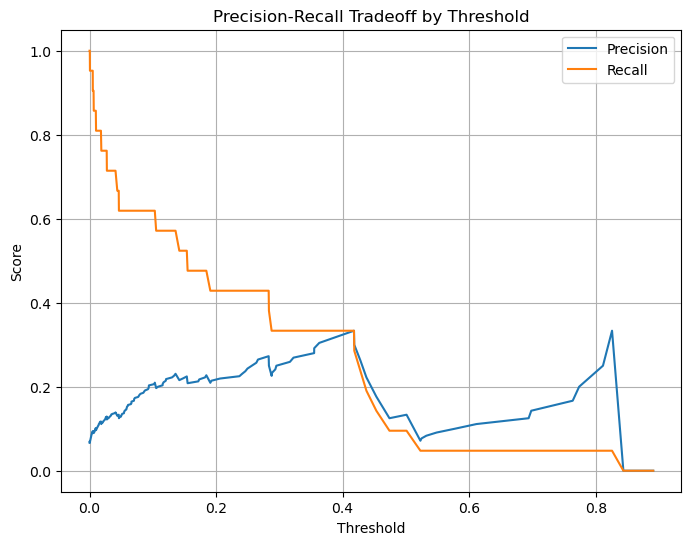

In [17]:
from sklearn.metrics import precision_recall_curve
import matplotlib.pyplot as plt

precisions, recalls, thresholds = precision_recall_curve(y_test, y_proba)

plt.figure(figsize=(8, 6))
plt.plot(thresholds, precisions[:-1], label='Precision')
plt.plot(thresholds, recalls[:-1], label='Recall')
plt.xlabel('Threshold')
plt.ylabel('Score')
plt.title('Precision-Recall Tradeoff by Threshold')
plt.legend()
plt.grid(True)
plt.show()

In [18]:
import numpy as np

diff = np.abs(precisions[:-1] - recalls[:-1])
cross_idx = np.argmin(diff)

print(f"교차 threshold: {thresholds[cross_idx]:.3f}")
print(f"그때 precision: {precisions[cross_idx]:.3f}")
print(f"그때 recall: {recalls[cross_idx]:.3f}")

교차 threshold: 0.418
그때 precision: 0.333
그때 recall: 0.333
